# 01 - Data acquisition and EDA
Heart Disease UCI (Cleveland, 303 patients). Downloads the raw file, cleans it and produces the EDA figures used in the report.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 140)

In [2]:
from heartrisk import data, eda, config
raw_path = data.download()
raw = data.load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Data quality checks
The raw file marks missing values with `?`. Only `ca` (4 rows) and `thal` (2 rows) have gaps. `num` ranges 0-4, so it is converted to a binary target (0 = no disease, 1-4 = disease).

In [3]:
print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nraw target (num) counts:'); print(raw['num'].value_counts().sort_index())
raw.describe().T.round(2)

ca      4
thal    2
dtype: int64

raw target (num) counts:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [4]:
df = data.make_clean_dataset()
print('clean shape', df.shape, '| duplicates removed:', len(raw) - len(df))
df[config.TARGET].value_counts()

clean shape (303, 14) | duplicates removed: 0


target
0    164
1    139
Name: count, dtype: int64

Missing values are left as NaN in the cleaned file on purpose. They are imputed inside the sklearn pipeline (median / most frequent), so the imputer only learns from training folds and the same step runs in the API.

In [5]:
info = eda.run(df)
info

{'rows': 303,
 'columns': 14,
 'missing_values': {'ca': 4, 'thal': 2},
 'class_counts': {'No disease': 164, 'Disease': 139},
 'top_correlations_with_target': {'thal': 0.526,
  'ca': 0.46,
  'exang': 0.432,
  'oldpeak': 0.425,
  'thalach': 0.417,
  'cp': 0.414},
 'figures': ['01_class_balance.png',
  '02_histograms.png',
  '03_correlation_heatmap.png',
  '04_categorical_disease_rate.png',
  '05_boxplots_by_outcome.png']}

## Class balance
164 vs 139 (54% / 46%) - mildly imbalanced, so plain accuracy is acceptable but recall and ROC-AUC are tracked as well.

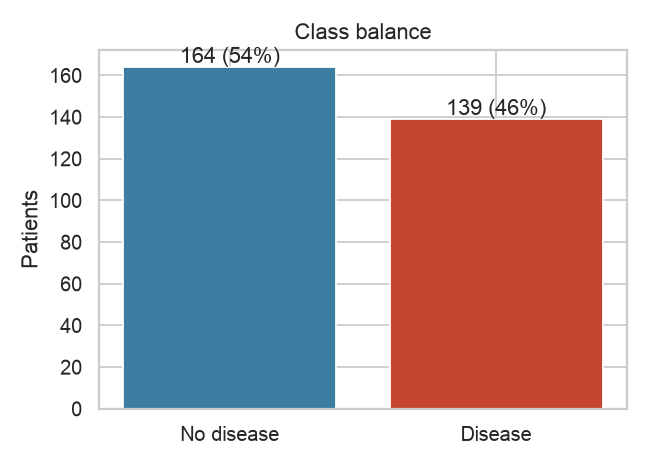

In [6]:
display(Image('reports/figures/01_class_balance.png'))

## Distributions by outcome
Patients with disease reach a lower max heart rate (`thalach`) and have higher ST depression (`oldpeak`). Cholesterol separates the classes very weakly.

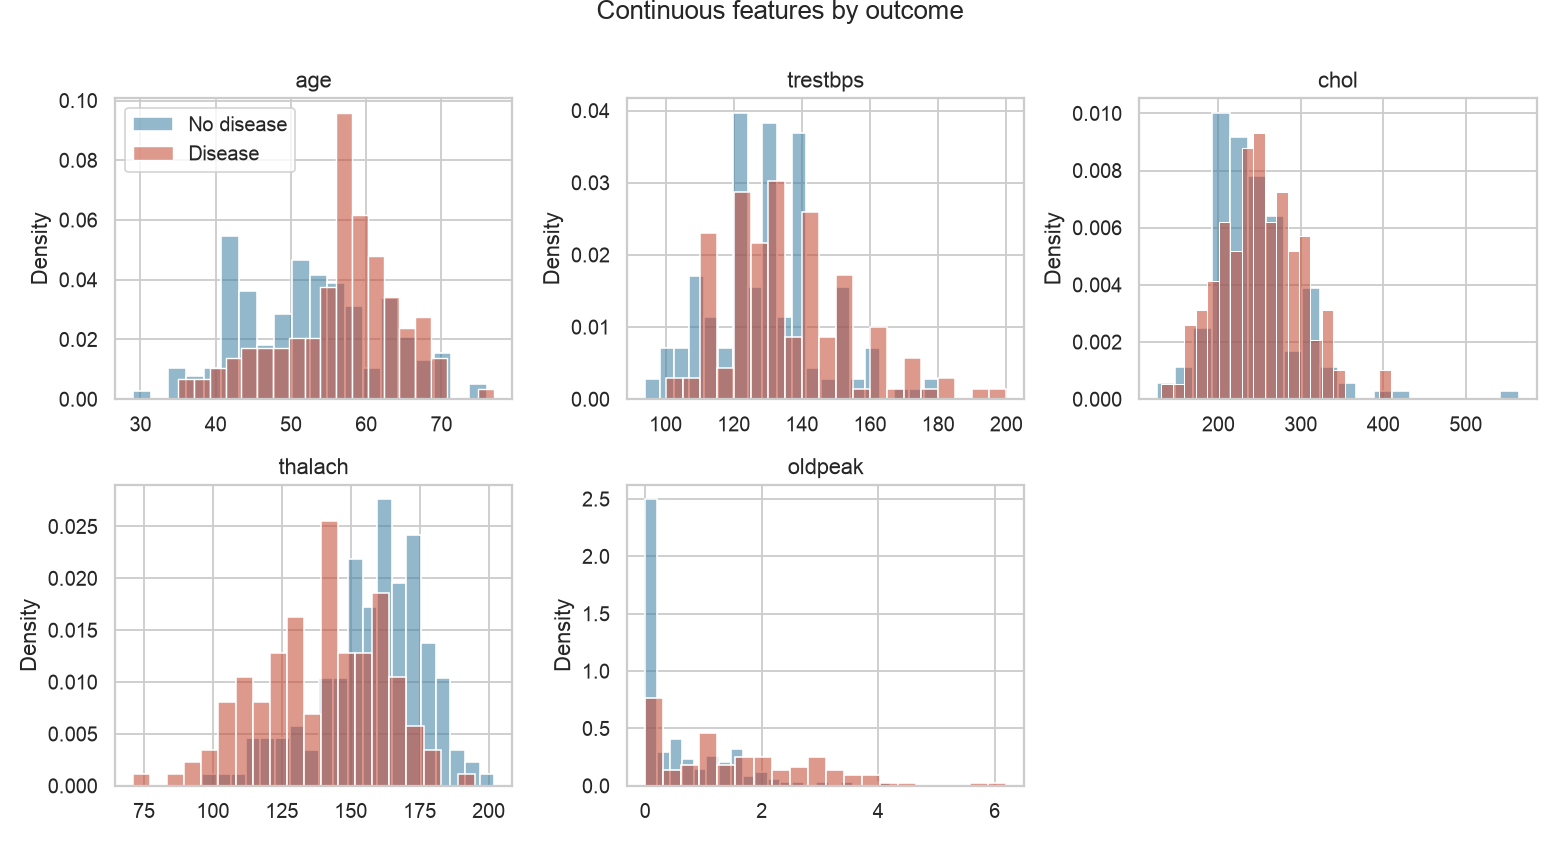

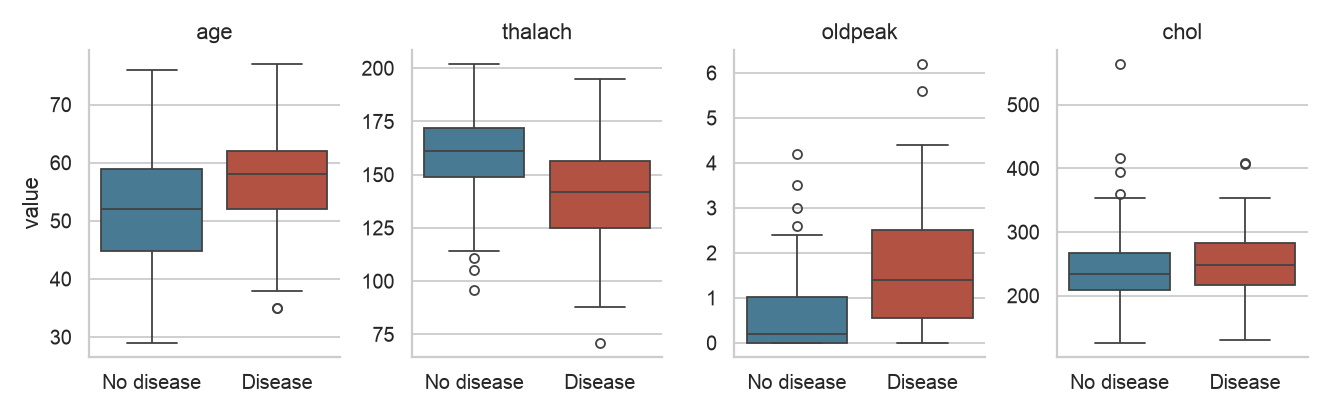

In [7]:
display(Image('reports/figures/02_histograms.png'))
display(Image('reports/figures/05_boxplots_by_outcome.png'))

## Correlations
`thal`, `ca`, `exang`, `oldpeak`, `thalach` and `cp` have the strongest link with the target. No pair of inputs is so correlated that it needs to be dropped.

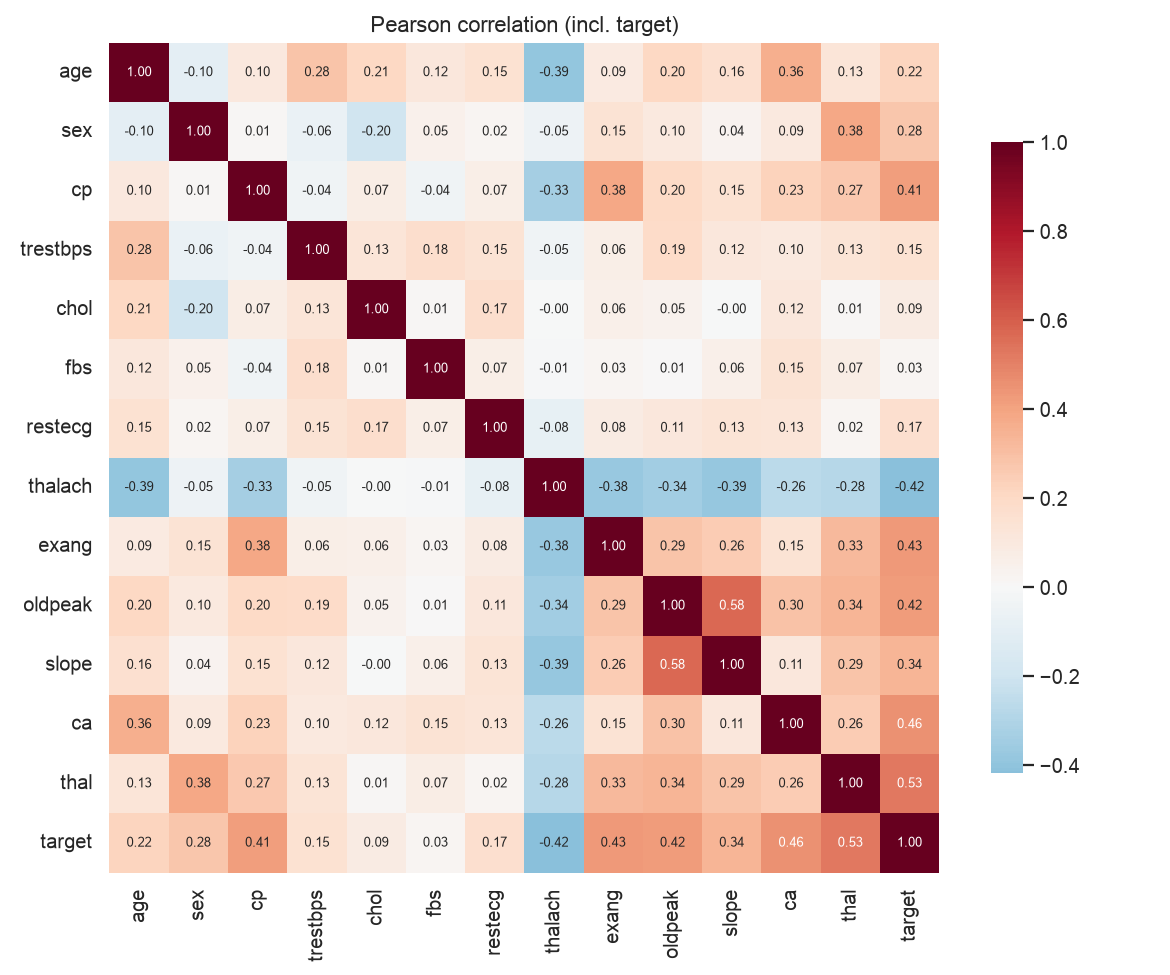

In [8]:
display(Image('reports/figures/03_correlation_heatmap.png'))

## Categorical features
Asymptomatic chest pain (`cp=4`) has a ~73% disease rate - counter-intuitive but well known for this dataset. `restecg=1` has only 4 patients, so one-hot encoding uses `handle_unknown='ignore'` to stay safe.

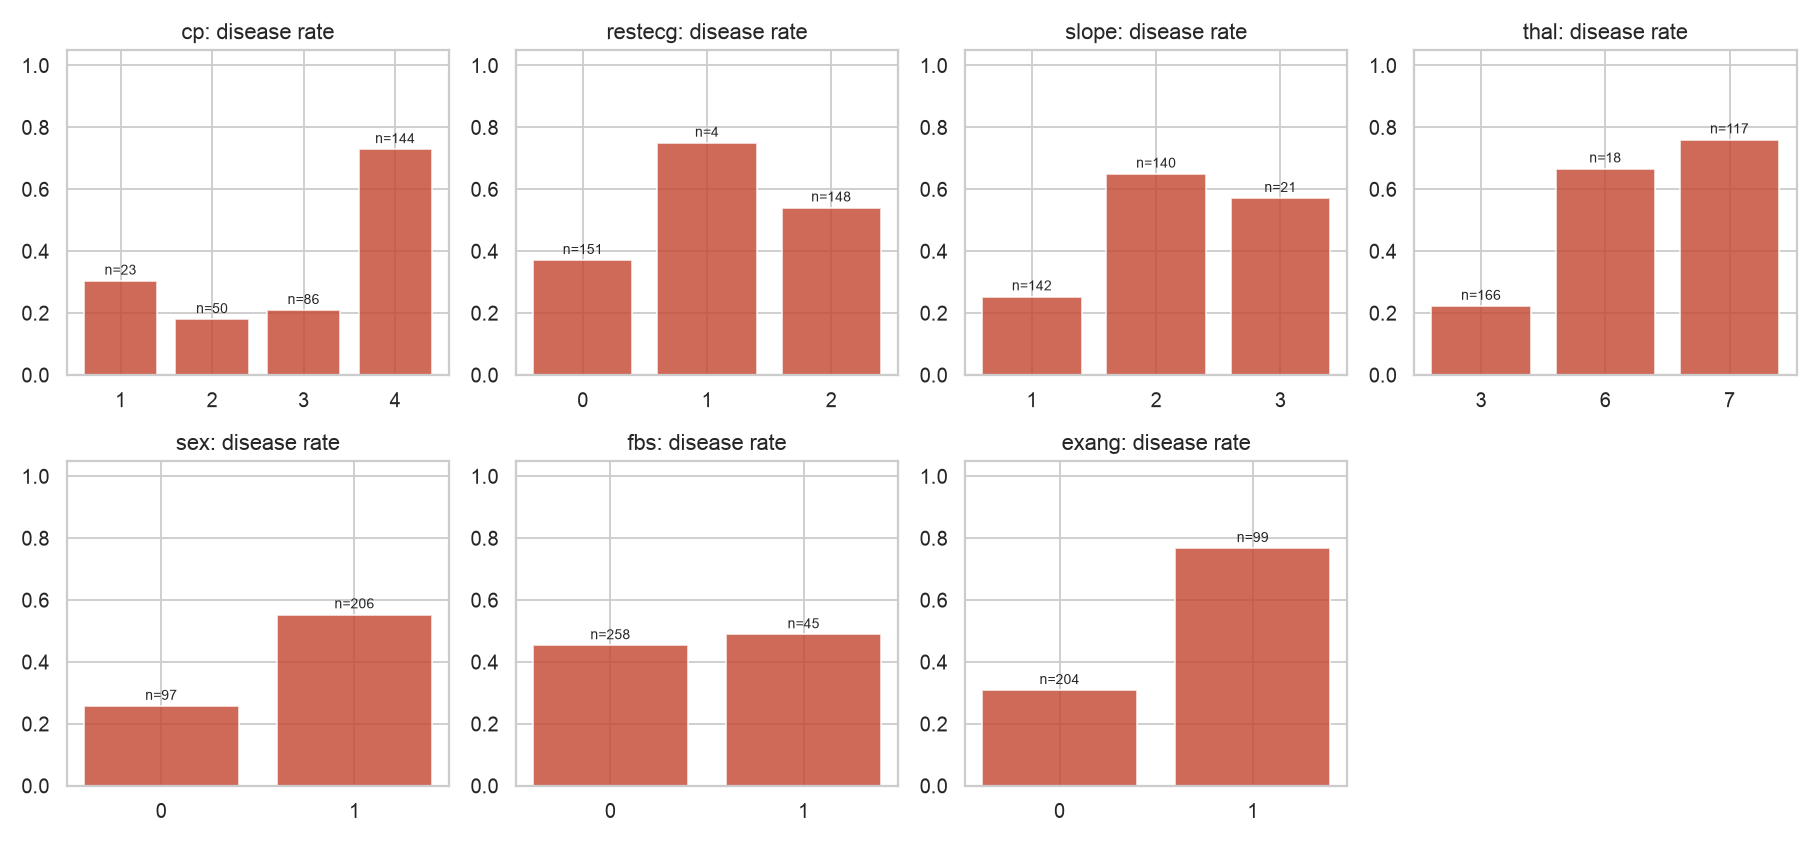

In [9]:
display(Image('reports/figures/04_categorical_disease_rate.png'))